# 01 · From a Question to a Grounded Answer

A language model answers from what it memorised during training. It has never read **your** documents, it
cannot know what changed last week, and when it does not know it will often make something up that sounds right.
**Retrieval-Augmented Generation (RAG)** fixes this by splitting the job in two: first *find* the passages
that matter, then ask the model to answer *using only those passages* and to say where each claim came from.

This first module builds the smallest complete RAG system there is, with nothing but NumPy-level Python, and
measures every step. No model is called and no key is needed: the point is to see the moving parts and where
they fail, before frameworks hide them.

**You will learn**
1. The anatomy of a RAG system and what each part is responsible for
2. Chunking: why *where* you cut the documents decides whether the answer can be found at all, measured
3. Lexical retrieval with BM25, written from scratch
4. How to measure retrieval honestly: hit@k and mean reciprocal rank (MRR) on a question battery
5. Grounded answers with citations, and refusing to answer when the documents are silent
6. The failure modes that the next modules fix

## 1. The anatomy of a RAG system

```
  documents ──► chunk ──► index ─────────────┐              (done once, offline)
                                             ▼
  question ──► retrieve top-k chunks ──► build prompt ──► generate ──► answer + citations
                    ▲                                          │
                    └──────────── evaluate and improve ◄───────┘   (done continuously)
```

| Stage | Question it answers | Typical failure |
|---|---|---|
| **Chunk** | What is the unit of text we can find and quote? | The fact is cut in half, or buried in a huge chunk |
| **Index / retrieve** | Which chunks are relevant to this question? | The right chunk exists but is not in the top *k* |
| **Prompt** | What does the model see? | Too many chunks, noise, contradictions |
| **Generate** | Can it answer *only* from what it was given? | It adds facts from memory, or ignores the chunks |
| **Evaluate** | Is it right, and why not when it is wrong? | Nobody looks, so nothing improves |

The rest of the course is these five stages, in this order, ending with a system that evaluates itself
and feeds its own mistakes back into the documentation.

## 2. The corpus

Every notebook in this course uses the same small, fictional document set: the operations handbook of an
offshore wind farm, *Harbourview*. It was written for the course, so it has no licence, no confidential
content and no real company in it. It has 22 short passages and every one holds a few checkable facts
(a wave limit, a deadline, a part count). We also have 16 questions with a known answer, two of which
the handbook deliberately cannot answer.

A small corpus is a feature here: you can read all of it, so when retrieval fails you can see *why*.

In [1]:
# The Harbourview handbook: 22 passages, fictional, written for this course
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

# (id, question, gold passage, fact the answer must contain); None = the handbook does not say
QUESTIONS = [
    ["q01", "What wave height stops the crew boats from sailing?", "p02", "1.5 m"],
    ["q02", "How often is the gearbox oil sampled?", "p07", "six months"],
    ["q03", "Who may work alone inside a nacelle?", "p03", "forbidden"],
    ["q04", "What is the rotor diameter of a turbine?", "p04", "164 m"],
    ["q05", "What do I do if the pitch fault comes back after a reset?", "p10", "replace the hydraulic accumulator"],
    ["q06", "When must a Level 3 alarm be attended on site?", "p09", "24 hours"],
    ["q07", "How soon must an injury be reported?", "p19", "one hour"],
    ["q08", "What is the largest amount of power the farm is allowed to send ashore?", "p21", "300 MW"],
    ["q09", "Which turbines are switched off at night in the autumn to protect birds?", "p14", "HV01 to HV08"],
    ["q10", "How many spare wind vanes are kept in stock?", "p16", "four wind vanes"],
    ["q11", "What qualification do I need before getting on the boat?", "p01", "GWO Basic Safety Training"],
    ["q12", "When can the turbines restart after a blackout?", "p12", "10 minutes"],
    ["q13", "When can a helicopter be used?", "p17", "medical evacuation"],
    ["q14", "What happens when a dolphin is seen near the piling work?", "p13", "pause"],
    ["q15", "What is the price of electricity per MWh?", None, None],
    ["q16", "Who is the chief executive of the operating company?", None, None],
]

In [2]:
import re, math, textwrap
import numpy as np
import matplotlib.pyplot as plt

print(len(PASSAGES), "passages,", sum(len(t.split()) for _, _, t in PASSAGES), "words in total")
print(len(QUESTIONS), "questions,", sum(q[2] is None for q in QUESTIONS), "of them unanswerable by design\n")
for pid, section, text in PASSAGES[:3]:
    print(f"[{pid}] {section}\n    {textwrap.fill(text, 100, subsequent_indent='    ')}\n")

22 passages, 560 words in total
16 questions, 2 of them unanswerable by design

[p01] Safety / Access
    Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer
    vessel. Certificates are checked at the harbour gate and expire after two years.

[p02] Safety / Weather limits
    Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed
    at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later.

[p03] Safety / Lone working
    Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people,
    and both must carry a personal locator beacon.



## 3. Chunking: where you cut decides what can be found

The handbook arrives as one long text, not as 22 tidy passages. The simplest splitter cuts every *N*
characters. It is fast and needs no understanding of the document, and it is how many first prototypes
start. Its flaw is that a cut can land in the middle of the very sentence that holds the answer.

We can measure that. For each answerable question we know the fact the answer must contain (for example
`1.5 m`). A chunking is *good for that question* when the **whole sentence that states the fact** survives
inside a single chunk: a chunk that holds `1.5 m` but lost *"...do not sail when the wave height exceeds"* is
useless as evidence. (Checking only the number would flatter every strategy.)

In [3]:
handbook = "\n\n".join(f"{section}\n{text}" for _, section, text in PASSAGES)
print(len(handbook), "characters in the handbook")

def fixed_chunks(text, size, overlap=0):
    step = size - overlap
    return [text[i:i + size] for i in range(0, max(len(text) - overlap, 1), step)]

def section_chunks(text):
    return [block for block in text.split("\n\n") if block.strip()]

def sentence_chunks(text, per_chunk=2):
    sentences = re.split(r"(?<=[.!?])\s+", text.replace("\n\n", " "))
    return [" ".join(sentences[i:i + per_chunk]) for i in range(0, len(sentences), per_chunk)]

all_sentences = [s for _, _, t in PASSAGES for s in re.split(r"(?<=[.!?])\s+", t)]
# the full sentence that states each answer fact
fact_sentences = [next(s for s in all_sentences if q[3] in s) for q in QUESTIONS if q[3]]

def fact_survival(chunks):
    # share of fact sentences that appear whole inside a single chunk
    return sum(any(s in c for c in chunks) for s in fact_sentences) / len(fact_sentences)

strategies = {
    "fixed 200 chars":               fixed_chunks(handbook, 200),
    "fixed 200 chars, overlap 50":   fixed_chunks(handbook, 200, 50),
    "fixed 400 chars":               fixed_chunks(handbook, 400),
    "2 sentences":                   sentence_chunks(handbook, 2),
    "by section (the document's own structure)": section_chunks(handbook),
}
print(f"{'strategy':44s}{'chunks':>8s}{'mean chars':>12s}{'sentences kept whole':>22s}")
for name, ch in strategies.items():
    print(f"{name:44s}{len(ch):8d}{np.mean([len(c) for c in ch]):12.0f}{fact_survival(ch):22.0%}")

3862 characters in the handbook
strategy                                      chunks  mean chars  sentences kept whole
fixed 200 chars                                   20         193                   71%
fixed 200 chars, overlap 50                       26         197                   86%
fixed 400 chars                                   10         386                   86%
2 sentences                                       23         166                  100%
by section (the document's own structure)         22         174                  100%


Blind fixed-size cuts break a share of the answer sentences, and overlap rescues part of them at the price
of more, repeated text. Cutting along the document's own structure keeps every sentence whole **and** makes
each chunk a unit a person would recognise (a section), which also gives you a natural citation:
*Safety / Weather limits*. (Read the exact figures in the table above; they depend on where the cuts land.)

**Rule of thumb:** use the structure that already exists (headings, sections, rows, paragraphs) before you
reach for a character count. When there is no structure, use sentence-aware windows with overlap. The size
is a trade-off: small chunks retrieve precisely but lose context; large chunks keep context but dilute the
match and cost more prompt tokens. We keep the section as the chunk for the rest of this course.

## 4. Lexical retrieval with BM25

The oldest good retrieval idea is also the strongest simple baseline: **rank chunks by the question's words
they contain**, giving more weight to rare words (*accumulator*) than to common ones (*the*). **BM25** is the
standard way to do it: a term-frequency score that saturates (the tenth repeat of a word adds little) and is
normalised by chunk length, multiplied by an inverse-document-frequency weight.

$$\text{score}(q,d)=\sum_{t\in q}\text{IDF}(t)\cdot\frac{f(t,d)\,(k_1+1)}{f(t,d)+k_1\,(1-b+b\,|d|/\overline{|d|})}$$

Here is a complete implementation. Search engines have run on this formula for decades, and it is what the
Social Pulse search in this project used for its retrieval.

In [4]:
STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you".split())

def tokens(text):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]

class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.tf = [{} for _ in docs]
        for i, d in enumerate(docs):
            for t in tokens(d):
                self.tf[i][t] = self.tf[i].get(t, 0) + 1
        self.len = np.array([sum(tf.values()) for tf in self.tf], dtype=float)
        self.avg = self.len.mean()
        df = {}
        for tf in self.tf:
            for t in tf:
                df[t] = df.get(t, 0) + 1
        n = len(docs)
        self.idf = {t: math.log(1 + (n - c + 0.5) / (c + 0.5)) for t, c in df.items()}

    def scores(self, query):
        s = np.zeros(len(self.tf))
        for t in set(tokens(query)):
            if t not in self.idf:
                continue
            for i, tf in enumerate(self.tf):
                f = tf.get(t, 0)
                if f:
                    s[i] += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.len[i] / self.avg))
        return s

chunks = [f"{section}. {text}" for _, section, text in PASSAGES]    # the section title is searchable too
ids = [p[0] for p in PASSAGES]
bm25 = BM25(chunks)

def search(index, query, k=3):
    s = index.scores(query)
    order = np.argsort(-s)[:k]
    return [(ids[i], float(s[i])) for i in order]

q = "What wave height stops the crew boats from sailing?"
print(q)
for pid, score in search(bm25, q):
    print(f"  {score:5.2f}  [{pid}] {chunks[ids.index(pid)][:90]}...")

What wave height stops the crew boats from sailing?
   6.30  [p02] Safety / Weather limits. Crew transfer vessels do not sail when the significant wave heigh...
   2.34  [p09] Faults / Alarm levels. Alarms have three levels. Level 1 is informational. Level 2 needs a...
   1.81  [p01] Safety / Access. Technicians must hold a valid GWO Basic Safety Training certificate befor...


## 5. Measuring retrieval honestly

"It seems to work" is not a measurement. We have 14 answerable questions with a known gold passage, so we
can compute:

* **hit@k**: the share of questions whose gold passage is among the top *k* results. hit@1 is the strict one;
  hit@3 is what matters when the generator gets three passages.
* **MRR** (mean reciprocal rank): the average of 1/rank of the gold passage (1 for first place, 0.5 for second,
  0 when it is not in the list). It rewards putting the right passage higher, not just somewhere.

Always report these on questions the system was **not tuned on**.

In [5]:
answerable = [q for q in QUESTIONS if q[2]]

def evaluate(index, k=3, verbose=False):
    ranks = []
    for qid, question, gold, _ in answerable:
        order = [pid for pid, _ in search(index, question, k=len(ids))]
        rank = order.index(gold) + 1
        ranks.append(rank)
        if verbose and rank > 1:
            print(f"  {qid} gold {gold} ranked {rank}: {question}")
    ranks = np.array(ranks)
    return dict(hit1=(ranks == 1).mean(), hit3=(ranks <= 3).mean(), mrr=(1 / ranks).mean()), ranks

metrics, ranks = evaluate(bm25, verbose=True)
print({k: round(float(v), 3) for k, v in metrics.items()})

  q08 gold p21 ranked 2: What is the largest amount of power the farm is allowed to send ashore?
  q11 gold p01 ranked 2: What qualification do I need before getting on the boat?
{'hit1': 0.857, 'hit3': 1.0, 'mrr': 0.929}


BM25 puts the right passage first for most questions out of the box, which is why it is a baseline you
should always run before anything fancier. Now read the ones it did not rank first next to their gold
passage: *"send ashore"* versus *"exported ... to the onshore substation"*, and *"qualification"* versus
*"certificate"*. The author and the asker used different words for the same idea.

That is the defining weakness of lexical search: **it matches words, not meaning.** If the person asking uses
different words from the author, the right passage can lose to one that merely shares a common word. Count
the words each question shares with its gold passage to see it.

In [6]:
for qid, question, gold, _ in answerable:
    q_terms = set(tokens(question))
    p_terms = set(tokens(chunks[ids.index(gold)]))
    overlap = q_terms & p_terms
    top = search(bm25, question, k=1)[0][0]
    flag = "" if top == gold else "   <-- missed"
    print(f"{qid}: {len(overlap)} shared words with its gold passage {sorted(overlap)}{flag}")

q01: 3 shared words with its gold passage ['crew', 'height', 'wave']
q02: 3 shared words with its gold passage ['gearbox', 'oil', 'sampled']
q03: 2 shared words with its gold passage ['inside', 'nacelle']
q04: 2 shared words with its gold passage ['diameter', 'rotor']
q05: 3 shared words with its gold passage ['fault', 'pitch', 'reset']
q06: 4 shared words with its gold passage ['3', 'alarm', 'level', 'site']
q07: 2 shared words with its gold passage ['injury', 'reported']
q08: 1 shared words with its gold passage ['power']   <-- missed
q09: 2 shared words with its gold passage ['night', 'turbines']
q10: 4 shared words with its gold passage ['spare', 'stock', 'vanes', 'wind']
q11: 1 shared words with its gold passage ['before']   <-- missed
q12: 2 shared words with its gold passage ['restart', 'turbines']
q13: 2 shared words with its gold passage ['helicopter', 'used']
q14: 2 shared words with its gold passage ['piling', 'work']


## 6. Generating a grounded answer, or refusing

The generator is the part that, in production, is a language model: *answer the question using only these
numbered passages, cite them as [1], [2], and say you cannot find it if the answer is not there.* Notebooks
03 and 04 plug in a real model. Here we use a deliberately simple **extractive** stand-in: it returns the
sentence of the top passage that shares the most words with the question. That is enough to show the two
behaviours that matter most:

1. **Citations**: every answer points back to the passage it came from, so a reader can check it.
2. **Refusal**: when the best score is too low, say *"not in the handbook"* instead of guessing. A RAG system
   that never refuses will answer the CEO question with whatever passage is least bad.

Where do we put the refusal threshold? From data, not by feel: compare the top score on questions the
handbook can answer with the top score on the ones it cannot.

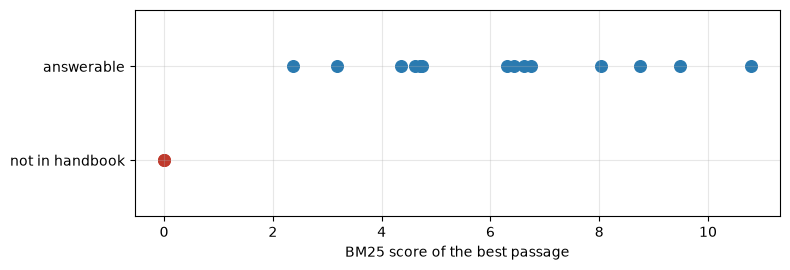

answerable: min 2.36 median 6.37 | unanswerable: max 0.00


In [7]:
top_scores = {qid: search(bm25, question, k=1)[0][1] for qid, question, gold, _ in QUESTIONS}
ans_scores = [top_scores[q[0]] for q in QUESTIONS if q[2]]
no_scores = [top_scores[q[0]] for q in QUESTIONS if not q[2]]

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.scatter(ans_scores, np.ones(len(ans_scores)), s=70, label="answerable", color="#2a7ab0")
ax.scatter(no_scores, np.zeros(len(no_scores)), s=70, label="not in the handbook", color="#c0392b")
ax.set_yticks([0, 1], ["not in handbook", "answerable"]); ax.set_xlabel("BM25 score of the best passage")
ax.set_ylim(-0.6, 1.6); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
print("answerable: min %.2f median %.2f | unanswerable: max %.2f" % (min(ans_scores), np.median(ans_scores), max(no_scores)))

In [8]:
THRESHOLD = 1.0     # from the picture above: the gap between the unanswerable scores (0) and the weakest answerable one

def sentences(text):
    return re.split(r"(?<=[.!?])\s+", text)

def answer(index, question, k=2, threshold=THRESHOLD):
    hits = search(index, question, k)
    if hits[0][1] < threshold:
        return "I cannot find that in the handbook.", []
    pid = hits[0][0]
    section, text = chunks[ids.index(pid)].split(". ", 1)
    q_terms = set(tokens(question))
    best = max(sentences(text), key=lambda s: len(q_terms & set(tokens(s))))
    return f"{best} [1]", [(1, pid, section)]

for qid, question, gold, fact in QUESTIONS:
    text, cites = answer(bm25, question)
    cite = f"   (source: {cites[0][1]}, {cites[0][2]})" if cites else ""
    print(f"{qid} {question}\n    -> {text}{cite}\n")

q01 What wave height stops the crew boats from sailing?
    -> Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. [1]   (source: p02, Safety / Weather limits)

q02 How often is the gearbox oil sampled?
    -> Gearbox oil is sampled every six months. [1]   (source: p07, Maintenance / Gearbox oil)

q03 Who may work alone inside a nacelle?
    -> Lone working inside a nacelle is forbidden. [1]   (source: p03, Safety / Lone working)

q04 What is the rotor diameter of a turbine?
    -> Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. [1]   (source: p04, Turbines / Specification)

q05 What do I do if the pitch fault comes back after a reset?
    -> A pitch system fault (code PF-203) usually means a low accumulator pressure. [1]   (source: p10, Faults / Pitch system)

q06 When must a Level 3 alarm be attended on site?
    -> Level 3 stops the turbine and needs a site visit within 24 hours 

## 7. Scoring the answers, and what the numbers say

A retrieval hit is not yet a correct answer, so grade the end result too. An answer counts as **correct**
when it contains the required fact, **correctly refused** when the question is unanswerable and the system
says so, and **wrong** otherwise (an answer to an unanswerable question is the worst case: a confident
invention).

In [9]:
def grade(index, threshold=THRESHOLD):
    out = {"correct": 0, "wrong: retrieval missed the passage": 0, "wrong: right passage, wrong sentence": 0,
           "missed (refused but answerable)": 0, "correctly refused": 0, "invented (answered, unanswerable)": 0}
    for qid, question, gold, fact in QUESTIONS:
        text, cites = answer(index, question, threshold=threshold)
        refused = not cites
        if gold:
            if refused:
                out["missed (refused but answerable)"] += 1
            elif fact in text:
                out["correct"] += 1
            else:
                out["wrong: retrieval missed the passage" if cites[0][1] != gold else "wrong: right passage, wrong sentence"] += 1
                print(f"  wrong: {qid} -> {text}")
        else:
            out["correctly refused" if refused else "invented (answered, unanswerable)"] += 1
    return out

print("with the threshold at", THRESHOLD)
for k, v in grade(bm25).items():
    print(f"{k:42s}{v:3d}")

with the threshold at 1.0
  wrong: q05 -> A pitch system fault (code PF-203) usually means a low accumulator pressure. [1]
  wrong: q08 -> Used oil, filters and composite offcuts are brought ashore and logged in the waste register. [1]
  wrong: q11 -> New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer. [1]
  wrong: q12 -> On loss of grid connection the turbines stop and the converters isolate. [1]
correct                                    10
wrong: retrieval missed the passage         2
wrong: right passage, wrong sentence        2
missed (refused but answerable)             0
correctly refused                           2
invented (answered, unanswerable)           0


The failures split into two kinds, and telling them apart is the first habit of RAG debugging. In *"retrieval
missed the passage"* the generator never had a chance. In *"right passage, wrong sentence"* retrieval did its
job and our crude extractive generator picked the wrong sentence of it; a language model reads the whole
passage and does not have this problem (it has others, which is why we grade it).

Three things to take away, and each is a module of this course:

1. **Retrieval is the ceiling.** The generator cannot do better than the passages it is given, and a
   language model cannot invent a missing one without hallucinating. Most of the effort in a real RAG system
   goes into retrieval. *Module 02 replaces word matching with meaning
   (embeddings), and shows why combining both beats either.*
2. **Answers that are right for the wrong reason are invisible without a battery.** We found these failures
   only because we had questions with known answers. *Module 07 builds that battery properly and
   grades with regular expressions and with a second model.*
3. **Someone has to look at the failures.** Here you read them by hand. In production the same loop is run
   by a second model, a *supervisor*, that judges every answer and turns the failures into fixes.
   *Module 08 builds it.*

## Exercises

1. Change `THRESHOLD` to 0 and to 4 and re-run the grading. Which errors appear on each side, and which is
   worse for a safety handbook?
2. Add a tiny stemmer (strip a trailing `s` and `ing`) to `tokens` and re-run section 5. Which misses does it
   fix, and which does it not (hint: *qualification* versus *certificate*)?
3. Rewrite three questions the way a hurried colleague would type them (`wave limit boats?`). How does hit@1
   change? This is the difference between a demo set and real traffic.
4. Try `fixed_chunks(handbook, 200)` as the chunking for retrieval instead of sections. How much does MRR
   drop, and why is the answer text worse for a reader even when the right chunk ranks first?